# Volatility Arbitrage and Delta Hedging on NIFTY Index Options

**Course:** MAC F244 — Stochastic Calculus and Application to Finance  
**Institution:** BITS Pilani, K K Birla Goa Campus  
**Instructor:** Mayank Goel  
**Team:** Arnav, Rohan, Joel, Ashwath and Advay

This standalone notebook reproduces the **entire** project end-to-end from a fresh kernel by reusing the project modules in `src/` (`pricing.py`, `simulation.py`, `backtest.py`, `robustness.py`), ensuring exact alignment with `run_project.py`. When opened standalone (e.g., in Google Colab), it automatically clones the GitHub repository so all modules and cleaned data are available.

In [1]:
import os
import subprocess
import sys
from pathlib import Path
from IPython.display import Image, display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    if (ROOT.parent / "src").exists():
        ROOT = ROOT.parent
    else:
        repo_dir = ROOT / "StochasticProject"
        if not (repo_dir / "src").exists():
            subprocess.run(
                ["git", "clone", "https://github.com/AshChan07/StochasticProject.git", str(repo_dir)],
                check=True,
            )
        ROOT = repo_dir
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".mplconfig"))
(ROOT / ".mplconfig").mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import pricing, simulation, backtest, robustness

# src.simulation and src.backtest set matplotlib backend to 'Agg' for headless CLI runs;
# restore the Jupyter/Colab inline backend so plt.show() renders figures inline.
try:
    plt.switch_backend("module://matplotlib_inline.backend_inline")
except Exception:
    pass

pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 160)
print(f"Project root: {ROOT}")

Project root: /Users/arnav/Developer/Academic_Projects/Stochastic_Calculus_Project


## 1. Mathematical Derivation (Ahmad & Wilmott, 2005)

Under the physical measure $\mathbb{P}$, the underlying follows geometric Brownian motion:
$$dS_t = \mu S_t\,dt + \sigma S_t\,dB_t.$$

An option marked at constant implied volatility $\sigma_i$ has value $V_i(S, t)$ satisfying the Black–Scholes PDE:
$$\frac{\partial V_i}{\partial t} + r S \frac{\partial V_i}{\partial S} + \frac{1}{2}\sigma_i^2 S^2 \frac{\partial^2 V_i}{\partial S^2} - r V_i = 0.$$

Holding one option, $-\Delta_h$ shares, and cash $C_t$ with initial wealth $W_0 = V_i - \Delta_h S_0 + C_0 = 0$ under self-financing rebalancing, Itô's formula yields the excess wealth increment:
$$dW_t - rW_t\,dt = \frac{1}{2}(\sigma^2 - \sigma_i^2)S_t^2\Gamma_i\,dt + (\Delta_i - \Delta_h)\big[(\mu - r)S_t\,dt + \sigma S_t\,dB_t\big].$$

- **Actual-Volatility Hedge ($\Delta_h = \Delta_\sigma$):** Continuous replication reproduces the terminal payoff $(S_T - K)^+$ from initial cost $V_\sigma(S_0, 0)$, giving the path-independent discounted terminal profit $e^{-rT}W_T = V_\sigma(S_0, 0) - V_i(S_0, 0)$.
- **Implied-Volatility Hedge ($\Delta_h = \Delta_i$):** Eliminates the Brownian diffusion term $dB_t$, leaving path-dependent terminal wealth $e^{-rT}W_T = \frac{1}{2}(\sigma^2 - \sigma_i^2)\int_0^T e^{-rt} S_t^2 \Gamma_i(S_t, t)\,dt$.

## 2. Monte Carlo Replication, Convergence & Drift Sensitivity

In [2]:
slope = simulation.run(ROOT)
sim_summary = pd.read_csv(ROOT / "results/simulation_summary.csv")
conv_df = pd.read_csv(ROOT / "results/convergence.csv")
drift_df = pd.read_csv(ROOT / "results/drift_sensitivity.csv")

print(f"Log-log convergence slope (theoretical N^(-1/2) rate => -0.50): {slope:.6f}")
print("\nSimulation Summary (20,000 paths, 252 rebalances):")
display(sim_summary)
print("\nConvergence Across Rebalancing Frequencies (6,000 paths):")
display(conv_df)
print("\nDrift Sensitivity (actual=30%, implied=20%):")
display(drift_df)

Log-log convergence slope (theoretical N^(-1/2) rate => -0.50): -0.495799

Simulation Summary (20,000 paths, 252 rebalances):


,actual,implied,rule,paths,rebalances,theory_actual,mean,std,se,skewness,excess_kurtosis,var_95,var_99,cvar_95,cvar_99,positive_fraction
0,0.15,0.2,actual,20000,252,-1.858925,-1.857915,0.293825,0.002078,0.028618,2.180016,2.332659,2.644921,2.524341,2.830923,0.00005
1,0.15,0.2,implied,20000,252,-1.858925,-1.764050,0.715786,0.005061,-0.328961,-0.467228,3.012935,3.473406,3.295483,3.695230,0.00000
2,0.30,0.2,actual,20000,252,3.780671,3.783992,0.621769,0.004397,0.047614,1.652195,0.000000,0.000000,-2.389828,-1.802432,1.00000
3,0.30,0.2,implied,20000,252,3.780671,3.740430,1.854661,0.013114,0.494631,-0.299666,0.000000,0.000000,-0.879259,-0.592976,1.00000



Convergence Across Rebalancing Frequencies (6,000 paths):


,rebalances,actual_error_std,implied_pnl_std,actual_mean,prediction
0,12,2.802510,3.277284,3.791299,3.780671
1,26,1.890306,2.542761,3.779061,3.780671
2,52,1.360479,2.203945,3.791701,3.780671
3,126,0.878297,1.924902,3.787417,3.780671
4,252,0.615246,1.853211,3.792226,3.780671
5,504,0.437633,1.774575,3.784911,3.780671
6,1008,0.311284,1.770154,3.778493,3.780671



Drift Sensitivity (actual=30%, implied=20%):


,mu,actual,implied,rule,paths,theory_actual,mean,std,error_vs_theory
0,-0.2,0.3,0.2,actual,10000,3.780671,3.803755,0.572308,0.023083
1,-0.2,0.3,0.2,implied,10000,3.780671,3.459794,1.767348,-0.320877
2,-0.1,0.3,0.2,actual,10000,3.780671,3.794031,0.601439,0.013360
3,-0.1,0.3,0.2,implied,10000,3.780671,3.688908,1.803527,-0.091763
4,0.0,0.3,0.2,actual,10000,3.780671,3.786828,0.619413,0.006157
5,0.0,0.3,0.2,implied,10000,3.780671,3.798122,1.824831,0.017451
6,0.1,0.3,0.2,actual,10000,3.780671,3.790277,0.615165,0.009606
7,0.1,0.3,0.2,implied,10000,3.780671,3.772072,1.870603,-0.008599
8,0.2,0.3,0.2,actual,10000,3.780671,3.791882,0.596105,0.011210
9,0.2,0.3,0.2,implied,10000,3.780671,3.579979,1.874730,-0.200692


Figure 1: Simulated Discounted P&L Distribution


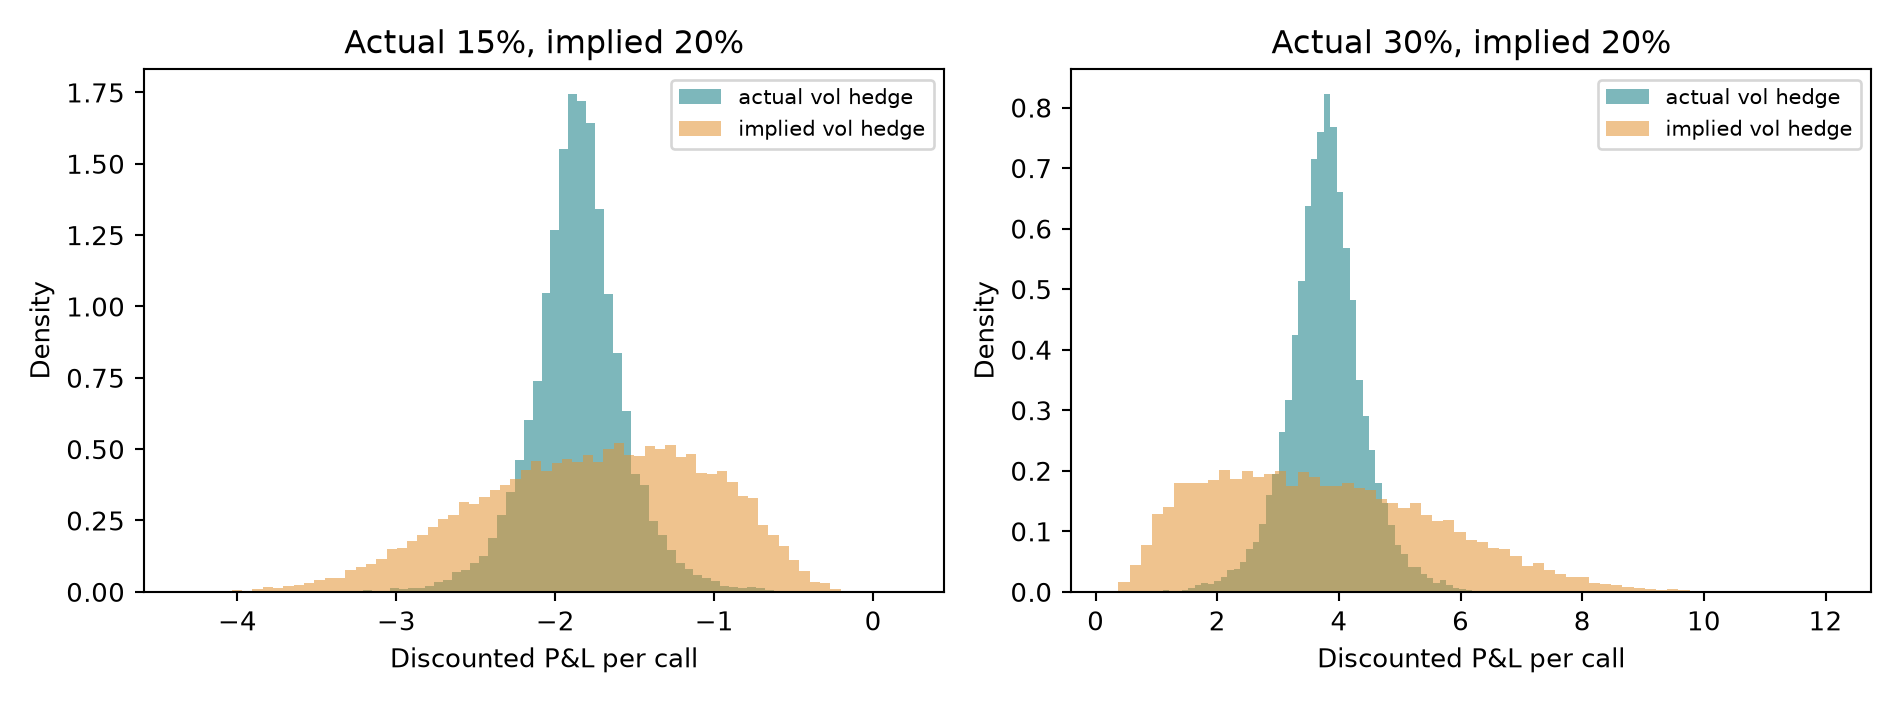

Figure 2: Discrete Hedging Error Convergence (log-log slope = -0.496)


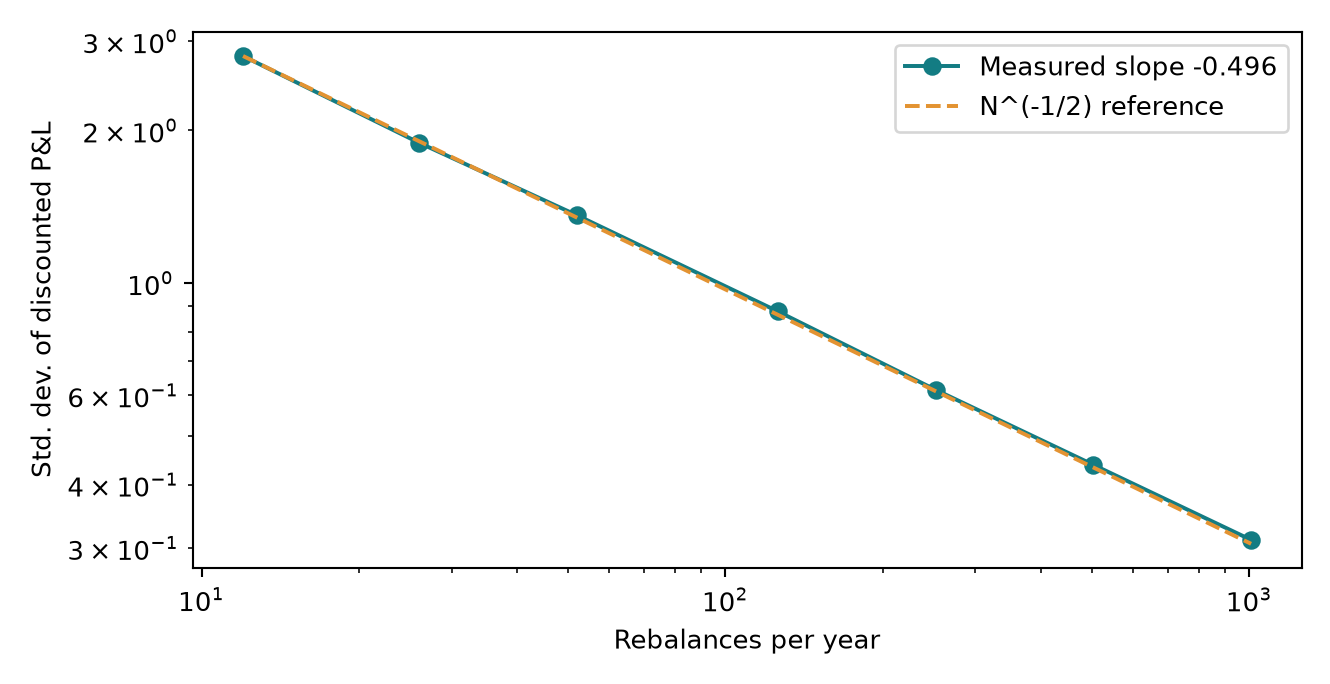

In [3]:
print("Figure 1: Simulated Discounted P&L Distribution")
display(Image(filename=str(ROOT / "results/figures/simulation_distribution.png")))

print("Figure 2: Discrete Hedging Error Convergence (log-log slope = -0.496)")
display(Image(filename=str(ROOT / "results/figures/convergence.png")))

## 3. Historical NIFTY Data Provenance, Volatility Diagnostics & Signal Design

- **Download Manifest (`data/download_manifest.csv`):** 389 requests total (370 downloaded trading sessions with SHA-256 hashes and 19 HTTP 404 weekdays).
- **Cleaned Options Chain (`data/clean/nifty_options_chain.csv.gz`):** 222,520 monthly-option records (193,392 with valid Black-76 implied volatilities).
- **ATM Panel (`data/clean/atm_panel.csv`):** Separate 370-row panel selecting the nearest ATM strike for the nearest monthly expiry 14–65 calendar days away (no GARCH column; `Market` fits exploratory GARCH(1,1) on training returns and writes `garch_forecast` to `data/clean/signal.csv`, while trading on EWMA only).
- **Horizon Mismatch & Execution:** The trading signal compares daily EWMA volatility (annualized to 252 sessions; evaluated against 5-session realized volatility in diagnostics) with IV from options 14–65 calendar days to expiry. Trades execute at the next session's open, hold for 5 sessions, exit at the first available session with $\le 7$ calendar days to expiry or at sample end, and new entries are blocked when $< 5$ sessions remain in the sample.

In [4]:
manifest = pd.read_csv(ROOT / "data/download_manifest.csv")
print("Manifest status counts:")
print(manifest["status"].value_counts().to_string())

market = backtest.Market(ROOT)
chain = pd.read_csv(ROOT / "data/clean/nifty_options_chain.csv.gz")
forecast_metrics = pd.read_csv(ROOT / "results/forecast_metrics.csv")

print(f"\nCleaned options chain rows: {len(chain):,} (valid IVs: {chain['iv'].notna().sum():,})")
print(f"Futures rows: {len(market.futures):,}")
print(f"ATM panel rows: {len(market.panel):,}")
print(f"Exploratory GARCH(1,1) training params: {market.garch_params}")
print("\nEWMA Forecast Diagnostics (vs 5-session realized volatility):")
display(forecast_metrics)
display(market.panel[["expiry", "strike", "forward", "implied_vol", "forecast_vol", "garch_forecast", "signal"]].dropna().head())

Manifest status counts:
status
downloaded         370
unavailable_404     19



Cleaned options chain rows: 222,520 (valid IVs: 193,392)
Futures rows: 1,110
ATM panel rows: 370
Exploratory GARCH(1,1) training params: {'omega': 0.00011596706132540445, 'alpha': 0.005353701735453065, 'beta': 0.43051845829899654}

EWMA Forecast Diagnostics (vs 5-session realized volatility):


,sample,n,rmse_vol,qlike
0,test,121,0.024711,0.163181
1,train,179,0.064152,0.420581


,expiry,strike,forward,implied_vol,forecast_vol,garch_forecast,signal
date,,,,,,,
2024-10-03,2024-10-31,25500.0,25475.70,0.119689,0.127046,0.226809,0.007357
2024-10-04,2024-10-31,25150.0,25173.85,0.130662,0.128452,0.228013,-0.002210
2024-10-07,2024-10-31,25000.0,24985.55,0.138471,0.129141,0.227431,-0.009330
2024-10-08,2024-10-31,25150.0,25131.65,0.132929,0.129726,0.227148,-0.003203
2024-10-09,2024-10-31,25100.0,25083.90,0.128503,0.125868,0.227024,-0.002635


## 4. Training Calibration (`2024-10-07` to `2025-06-30`)

Among candidate thresholds $k \in \{0.00, 0.01, 0.02, 0.03\}$ (0 to 3 volatility percentage points) with at least 10 calibration trades under each rule, the selected threshold maximizes the **average of total calibration-period net P&L across the two hedge rules**. At $k = 0.03$, both rules execute 10 trades and their totals average **230.25 index points**.

In [5]:
cal_rows = []
for k in [0.00, 0.01, 0.02, 0.03]:
    for rule in ["implied", "forecast"]:
        _, _, met, _ = backtest.run(market, "2024-10-07", "2025-06-30", threshold=k, rule=rule)
        cal_rows.append(met)
cal_df = pd.DataFrame(cal_rows)
display(cal_df[["threshold", "rule", "trades", "net_pnl", "cost", "max_drawdown_points", "sharpe_excess"]])

agg = cal_df.groupby("threshold").agg(avg_total_net_pnl=("net_pnl", "mean"), min_trades=("trades", "min"))
selected_k = float(agg[agg["min_trades"] >= 10]["avg_total_net_pnl"].idxmax())
print(f"Selected threshold k = {selected_k:.2f} ({selected_k*100:.0f} volatility percentage points)")
display(agg)

,threshold,rule,trades,net_pnl,cost,max_drawdown_points,sharpe_excess
0,0.00,implied,30,-417.275036,149.128817,1088.082312,-0.549527
1,0.00,forecast,30,-481.139961,150.644888,1098.548605,-0.624478
2,0.01,implied,21,-313.036294,109.179000,586.218594,-0.518512
3,0.01,forecast,21,-326.335024,111.124414,593.704836,-0.534864
4,0.02,implied,15,-81.768955,81.922050,525.067171,-0.169399
5,0.02,forecast,15,-99.818820,83.125774,535.511286,-0.201382
6,0.03,implied,10,229.632021,55.416934,383.515408,0.581647
7,0.03,forecast,10,230.860640,56.610879,400.564127,0.590268


Selected threshold k = 0.03 (3 volatility percentage points)


,avg_total_net_pnl,min_trades
threshold,,
0.00,-449.207498,30
0.01,-319.685659,21
0.02,-90.793888,15
0.03,230.246330,10


## 5. Out-of-Sample Test Backtest (`2025-07-01` to `2025-12-31`)

Across 126 test sessions at $k = 0.03$, only 3 short straddle trades trigger. The Sharpe ratio shown (`sharpe_excess`) is the **annualized daily P&L Sharpe** (annualized daily net P&L without a separate risk-free deduction).

In [6]:
# Run the full experiment to also generate volatility.png and historical_pnl.png
backtest.experiment(ROOT)

test_metrics = []
test_curves = {}
test_trades = {}
for rule in ["implied", "forecast"]:
    d, t, met, _ = backtest.run(market, "2025-07-01", "2025-12-31", threshold=selected_k, rule=rule)
    test_metrics.append(met)
    test_curves[rule] = d
    test_trades[rule] = t

print("Test-period summary metrics:")
display(pd.DataFrame(test_metrics)[["rule", "sessions", "trades", "net_pnl", "gross_pnl", "cost", "max_drawdown_points", "sharpe_excess"]])

print("Implied-vol hedge test trades:")
display(test_trades["implied"])
print("Forecast-vol hedge test trades:")
display(test_trades["forecast"])

Test-period summary metrics:


,rule,sessions,trades,net_pnl,gross_pnl,cost,max_drawdown_points,sharpe_excess
0,implied,126,3,159.224249,171.508079,12.283830,55.775798,1.632304
1,forecast,126,3,165.804238,180.115444,14.311206,65.696072,1.543794


Implied-vol hedge test trades:


,trade_id,entry_date,exit_date,expiry,strike,direction,entry_signal,pnl,holding_sessions
0,1,2025-10-29,2025-11-06,2025-11-25,26100.0,-1,-0.031384,34.710005,5
1,2,2025-11-11,2025-11-18,2025-11-25,25700.0,-1,-0.032045,56.865084,5
2,3,2025-11-19,2025-11-26,2025-12-30,26150.0,-1,-0.033745,67.649160,5


Forecast-vol hedge test trades:


,trade_id,entry_date,exit_date,expiry,strike,direction,entry_signal,pnl,holding_sessions
0,1,2025-10-29,2025-11-06,2025-11-25,26100.0,-1,-0.031384,40.069396,5
1,2,2025-11-11,2025-11-18,2025-11-25,25700.0,-1,-0.032045,68.506039,5
2,3,2025-11-19,2025-11-26,2025-12-30,26150.0,-1,-0.033745,57.228803,5


Figure 3: NIFTY EWMA Forecast vs ATM Implied Volatility


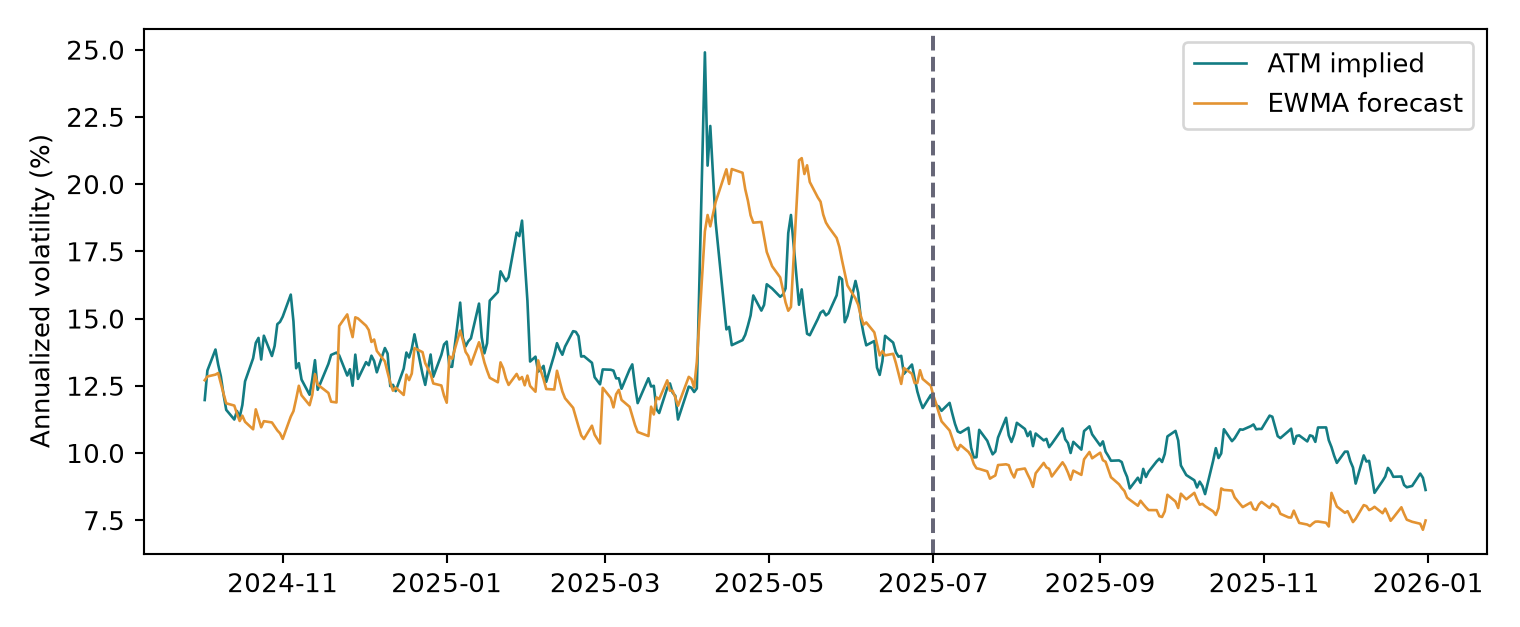

Figure 4: Test-Period Cumulative Net P&L (k = 0.03)


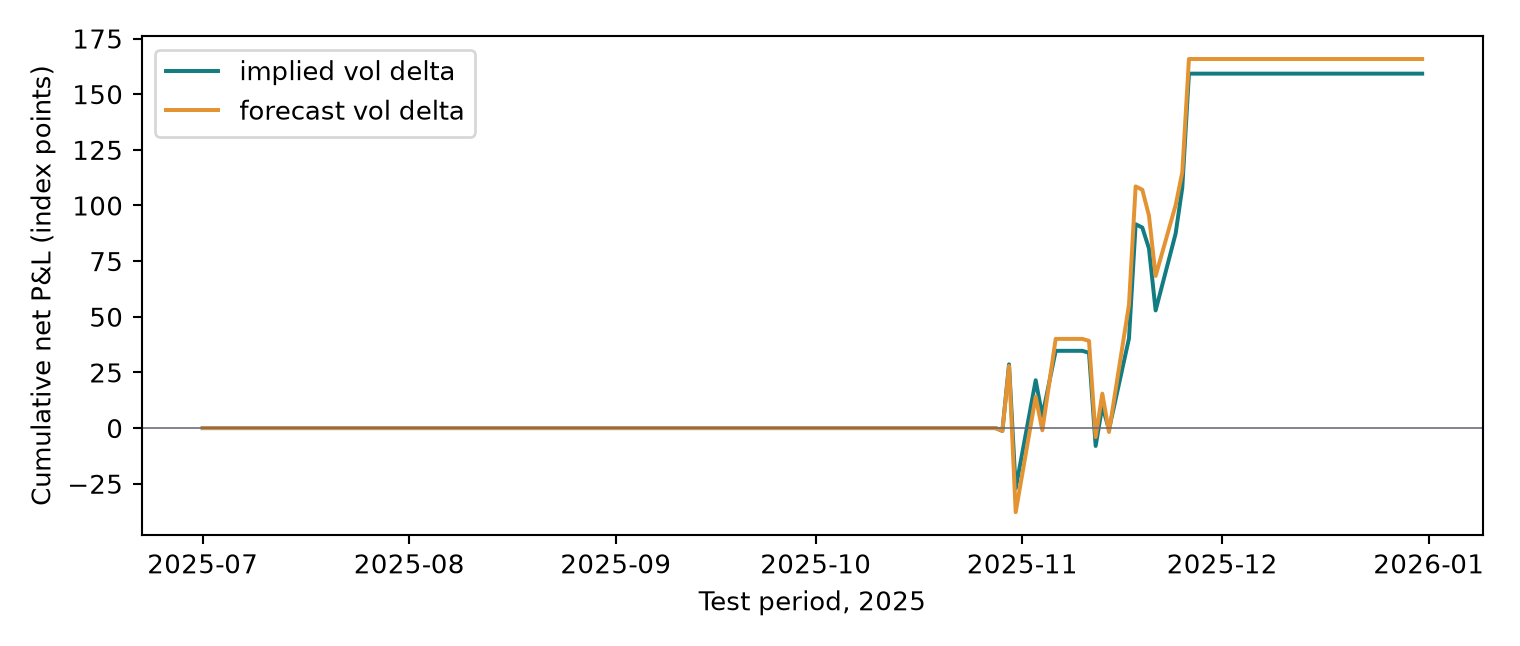

<Figure size 900x400 with 1 Axes>

In [7]:
print("Figure 3: NIFTY EWMA Forecast vs ATM Implied Volatility")
display(Image(filename=str(ROOT / "results/figures/volatility.png")))

print("Figure 4: Test-Period Cumulative Net P&L (k = 0.03)")
display(Image(filename=str(ROOT / "results/figures/historical_pnl.png")))

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(test_curves["implied"]["date"], test_curves["implied"]["cumulative_pnl"], label="Implied-Vol Delta Hedge", lw=2)
ax.plot(test_curves["forecast"]["date"], test_curves["forecast"]["cumulative_pnl"], label="Forecast-Vol Delta Hedge", lw=2)
ax.axhline(0, color="gray", lw=0.8, ls="--")
ax.set_title("Test-Period Cumulative Net P&L (k = 0.03, 3 Volatility Percentage Points)")
ax.set_ylabel("Cumulative Net P&L (Index Points)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Sensitivity, Rebalancing Frequency, Benchmark & Post-Hoc Threshold Diagnostics

In [8]:
cost_sens = []
for cm in [0, 1, 2, 5]:
    for rule in ["implied", "forecast"]:
        _, _, met, _ = backtest.run(market, "2025-07-01", "2025-12-31", threshold=selected_k, rule=rule, cost_mult=cm)
        cost_sens.append(met)
print("Transaction cost multiplier sensitivity (k = 0.03):")
display(pd.DataFrame(cost_sens)[["cost_multiplier", "rule", "trades", "net_pnl", "cost", "sharpe_excess"]])

rebal_sens = []
for freq in [1, 2, 5]:
    for rule in ["implied", "forecast"]:
        _, _, met, _ = backtest.run(market, "2025-07-01", "2025-12-31", threshold=selected_k, rule=rule, rebalance=freq)
        rebal_sens.append(met)
print("Rebalancing frequency sensitivity (k = 0.03):")
display(pd.DataFrame(rebal_sens)[["rebalance_sessions", "rule", "trades", "net_pnl", "cost", "sharpe_excess"]])

_, _, bench_met, _ = backtest.run_benchmark(market, "2025-07-01", "2025-12-31")
print("Naive rolling short ATM straddle benchmark (test period):")
display(pd.DataFrame([bench_met])[["rule", "trades", "net_pnl", "cost", "max_drawdown_points", "sharpe_excess"]])

thresh_sens = []
for kk in [0.00, 0.01, 0.02, 0.03]:
    for rule in ["implied", "forecast"]:
        _, _, met, _ = backtest.run(market, "2025-07-01", "2025-12-31", threshold=kk, rule=rule)
        thresh_sens.append(met)
print("Post-hoc test threshold diagnostic (performed after selection; k remains locked at 0.03):")
display(pd.DataFrame(thresh_sens)[["threshold", "rule", "trades", "net_pnl", "cost", "max_drawdown_points", "sharpe_excess"]])

Transaction cost multiplier sensitivity (k = 0.03):


,cost_multiplier,rule,trades,net_pnl,cost,sharpe_excess
0,0,implied,3,171.515947,0.000000,1.740081
1,0,forecast,3,180.124500,0.000000,1.659939
2,1,implied,3,159.224249,12.283830,1.632304
3,1,forecast,3,165.804238,14.311206,1.543794
4,2,implied,3,146.932552,24.567660,1.521329
5,2,forecast,3,151.483976,28.622411,1.424308
6,5,implied,3,110.057459,61.419150,1.170126
7,5,forecast,3,108.523189,71.556028,1.047012


Rebalancing frequency sensitivity (k = 0.03):


,rebalance_sessions,rule,trades,net_pnl,cost,sharpe_excess
0,1,implied,3,159.224249,12.283830,1.632304
1,1,forecast,3,165.804238,14.311206,1.543794
2,2,implied,3,167.253857,11.362625,1.829196
3,2,forecast,3,173.872240,13.113723,1.754134
4,5,implied,3,147.314815,6.948898,1.712555
5,5,forecast,3,148.609094,7.026823,1.708544


Naive rolling short ATM straddle benchmark (test period):


,rule,trades,net_pnl,cost,max_drawdown_points,sharpe_excess
0,implied,21,306.576973,91.878826,303.987367,1.087438


Post-hoc test threshold diagnostic (performed after selection; k remains locked at 0.03):

,threshold,rule,trades,net_pnl,cost,max_drawdown_points,sharpe_excess
0,0.00,implied,21,46.085136,91.878826,303.987367,0.162870
1,0.00,forecast,21,103.495038,98.852756,232.029392,0.360620
2,0.01,implied,17,389.757851,76.081895,230.906975,1.492265
3,0.01,forecast,17,413.330634,82.544961,201.580435,1.589974
4,0.02,implied,7,46.355913,32.074053,195.978687,0.293372
5,0.02,forecast,7,137.253956,35.984222,115.404274,0.902583
6,0.03,implied,3,159.224249,12.283830,55.775798,1.632304
7,0.03,forecast,3,165.804238,14.311206,65.696072,1.543794


## 7. Exploratory Robustness Diagnostics (`src/robustness.py`)

Includes Black-76 futures replication and Greek P&L attribution ($\Delta, \Gamma, \Theta, \text{Vega}$) on the test-period trades.

In [9]:
fut_pnl, fut_target = robustness.simulate_futures(n=252, paths=5000)
print(f"Futures replication (30% actual vs 20% implied): theoretical = {fut_target:.4f}, actual-vol hedge mean = {fut_pnl[0].mean():.4f} (std {fut_pnl[0].std(ddof=1):.4f}), implied-vol hedge mean = {fut_pnl[1].mean():.4f} (std {fut_pnl[1].std(ddof=1):.4f})")

greek_attr = robustness.attribution(market, test_curves["implied"], test_trades["implied"])
print("\nDaily Greek attribution for test-period implied-vol hedge:")
display(greek_attr[["date", "option_pnl", "delta", "gamma", "theta", "vega", "residual", "valid"]])

Futures replication (30% actual vs 20% implied): theoretical = 3.7649, actual-vol hedge mean = 3.7756 (std 0.6130), implied-vol hedge mean = 3.8137 (std 1.8537)

Daily Greek attribution for test-period implied-vol hedge:


,date,option_pnl,delta,gamma,theta,vega,residual,valid
0,2025-10-30,30.00,-2.778082,-2.805800,11.541984,24.621190,-0.579291,True
1,2025-10-31,-27.00,22.006144,-18.512078,11.227337,-42.515818,0.794415,True
2,2025-11-03,41.30,-9.465754,-7.574646,36.810570,23.815490,-2.285660,True
3,2025-11-04,-19.15,-3.412890,-0.127277,12.092279,-28.582016,0.879904,True
4,2025-11-06,2.50,-31.266966,-9.537143,25.979162,21.572282,-4.247335,True
5,2025-11-12,-41.70,-10.399930,-27.402621,15.491380,-21.246472,1.857644,True
6,2025-11-13,14.05,-8.524426,-0.456060,15.605713,8.058331,-0.633559,True
7,2025-11-14,9.05,18.021451,-1.542651,15.424882,-23.894764,1.041082,True
8,2025-11-17,3.35,-31.067644,-7.153587,53.669066,-12.987156,0.889322,True
9,2025-11-18,47.55,-6.884806,-0.132617,18.913189,41.895953,-6.241719,True


## 8. Automated Unit & Audit Test Suite (35 Tests)

In [10]:
import unittest

suite = unittest.defaultTestLoader.discover(str(ROOT / "tests"))
runner = unittest.TextTestRunner(verbosity=1)
result = runner.run(suite)
assert result.wasSuccessful(), "Test suite failed!"

.

.

.

.

.

.

... (26 outputs left out)

.

.

.

----------------------------------------------------------------------
Ran 35 tests in 2.633s

OK
